# Term Deposit Subscription: Model Training

This notebook walks through the training of the model used by the web app. It reuses the same cleaning and pipeline code as `ml/train_model.py` (imported, not copied), so the results match the script exactly.

**Steps:** 1) load and clean data, 2) explore, 3) split, 4) baseline, 5) train, 6) evaluate, 7) feature importance, 8) load the saved model the way the app does.

In [1]:
import sys
from pathlib import Path

# Find the project root whether the notebook runs from notebooks/ or the root
ROOT = Path.cwd()
if not (ROOT / "ml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score,
    precision_score, recall_score, roc_auc_score, roc_curve, classification_report,
)
from sklearn.model_selection import train_test_split

from ml import config as cfg
from ml.train_model import load_and_clean, build_pipeline

pd.set_option("display.max_columns", 30)
print("Project root:", ROOT)

Matplotlib is building the font cache; this may take a moment.


Project root: c:\Users\Dhiraj\Downloads\Projects\term_deposit_predictor


## 1. Load and clean the data
Duplicates are removed, `duration` is dropped (it is only known after the call, so it would leak the answer), and the target is mapped yes -> 1, no -> 0.

In [2]:
df = load_and_clean()
df.head()

Loaded 41,188 rows and 21 columns
Removed 12 fully duplicated rows
Missing values (real blanks): none


,age,campaign,previous,job,marital,education,housing,loan,contact,month,poutcome,y
0,56,1,0,housemaid,married,basic.4y,no,no,telephone,may,nonexistent,0
1,57,1,0,services,married,high.school,no,no,telephone,may,nonexistent,0
2,37,1,0,services,married,high.school,yes,no,telephone,may,nonexistent,0
3,40,1,0,admin.,married,basic.6y,no,no,telephone,may,nonexistent,0
4,56,1,0,services,married,high.school,no,yes,telephone,may,nonexistent,0


In [3]:
print(df.shape)
df.dtypes

(41176, 12)


age           int64
campaign      int64
previous      int64
job          object
marital      object
education    object
housing      object
loan         object
contact      object
month        object
poutcome     object
y             int64
dtype: object

## 2. Exploratory analysis

Share of clients who subscribed: 11.3%


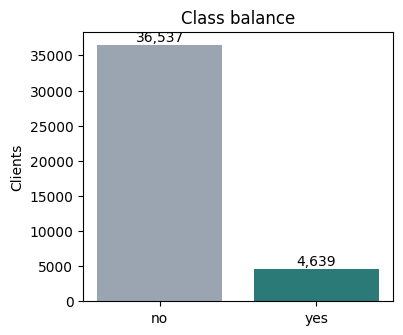

In [4]:
counts = df[cfg.TARGET].value_counts().sort_index()
share = df[cfg.TARGET].mean()
print(f"Share of clients who subscribed: {share:.1%}")

fig, ax = plt.subplots(figsize=(4, 3.5))
ax.bar(["no", "yes"], counts.values, color=["#9aa5b1", "#2b7a78"])
ax.set_title("Class balance")
ax.set_ylabel("Clients")
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.show()

C:\Users\Dhiraj\AppData\Local\Temp\ipykernel_27792\727995176.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rate = df.groupby(series)[cfg.TARGET].mean().sort_values(ascending=False) * 100


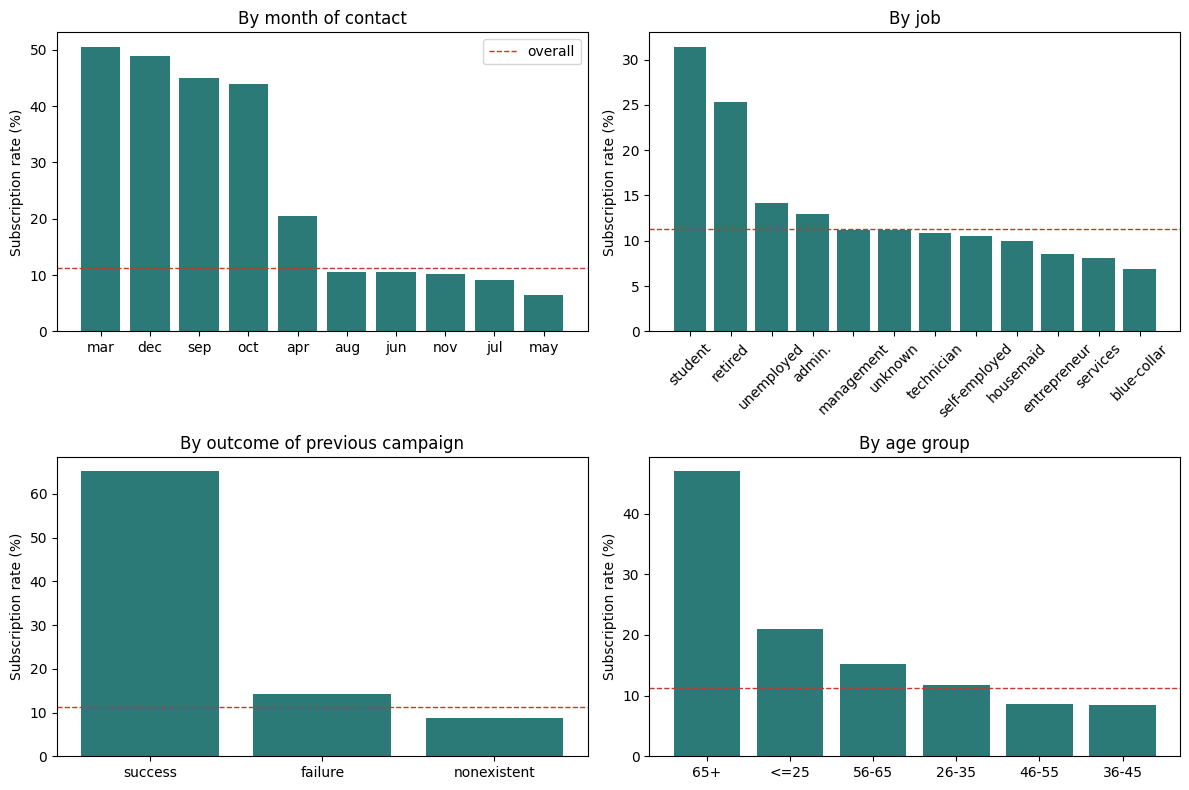

In [5]:
def rate_plot(ax, series, title, rotate=0):
    rate = df.groupby(series)[cfg.TARGET].mean().sort_values(ascending=False) * 100
    ax.bar(rate.index.astype(str), rate.values, color="#2b7a78")
    ax.axhline(df[cfg.TARGET].mean() * 100, color="#c0392b", ls="--", lw=1, label="overall")
    ax.set_title(title)
    ax.set_ylabel("Subscription rate (%)")
    ax.tick_params(axis="x", rotation=rotate)

age_group = pd.cut(df["age"], [0, 25, 35, 45, 55, 65, 120],
                   labels=["<=25", "26-35", "36-45", "46-55", "56-65", "65+"])

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
rate_plot(axes[0, 0], df["month"], "By month of contact")
rate_plot(axes[0, 1], df["job"], "By job", rotate=45)
rate_plot(axes[1, 0], df["poutcome"], "By outcome of previous campaign")
rate_plot(axes[1, 1], age_group, "By age group")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

**Reading the plots:** only about 11% of clients subscribe, so the classes are imbalanced. A previous successful campaign is by far the strongest signal, and the rate also varies a lot by month and age group.

## 3. Train/test split
Stratified, so the yes/no ratio is the same in both sets. Same size and random seed as the script.

In [6]:
X = df[cfg.FEATURES]
y = df[cfg.TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=cfg.TEST_SIZE, stratify=y, random_state=cfg.RANDOM_STATE
)
print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows")
print(f"'yes' share  train: {y_train.mean():.1%} | test: {y_test.mean():.1%}")

Train: 32,940 rows | Test: 8,236 rows
'yes' share  train: 11.3% | test: 11.3%


## 4. Baseline: always predict "no"
This shows why accuracy alone is misleading on imbalanced data.

In [7]:
base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
bp = base.predict(X_test)
print(f"Baseline accuracy: {accuracy_score(y_test, bp):.3f}")
print(f"Baseline recall:   {recall_score(y_test, bp):.3f}  (finds no subscribers at all)")

Baseline accuracy: 0.887
Baseline recall:   0.000  (finds no subscribers at all)


## 5. Train the model
A scikit-learn `Pipeline`: imputation + one-hot encoding + Random Forest (300 trees, `min_samples_leaf=5`, `class_weight="balanced"`).

In [8]:
pipeline = build_pipeline()
pipeline.fit(X_train, y_train)
pipeline

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['age', 'campaign',
                                                   'previous']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['job', 'marital',
                                                   'education', 'housing',
                                                   'loan', 'contact', 'month',
                                                   'poutcome'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced',
                                        min_samples_leaf=5, n_estimators=300,
                                        n_jobs=-1, random_state=42))])

## 6. Evaluate on the test set

In [9]:
pred = pipeline.predict(X_test)
proba = pipeline.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    "Random Forest": {
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba),
    },
    "Always 'no'": {
        "accuracy": accuracy_score(y_test, bp),
        "precision": precision_score(y_test, bp, zero_division=0),
        "recall": recall_score(y_test, bp),
        "f1": f1_score(y_test, bp),
        "roc_auc": 0.5,
    },
}).round(3)
results

,Random Forest,Always 'no'
accuracy,0.854,0.887
precision,0.394,0.000
recall,0.548,0.000
f1,0.459,0.000
roc_auc,0.774,0.500


              precision    recall  f1-score   support

          no       0.94      0.89      0.92      7308
         yes       0.39      0.55      0.46       928

    accuracy                           0.85      8236
   macro avg       0.67      0.72      0.69      8236
weighted avg       0.88      0.85      0.86      8236



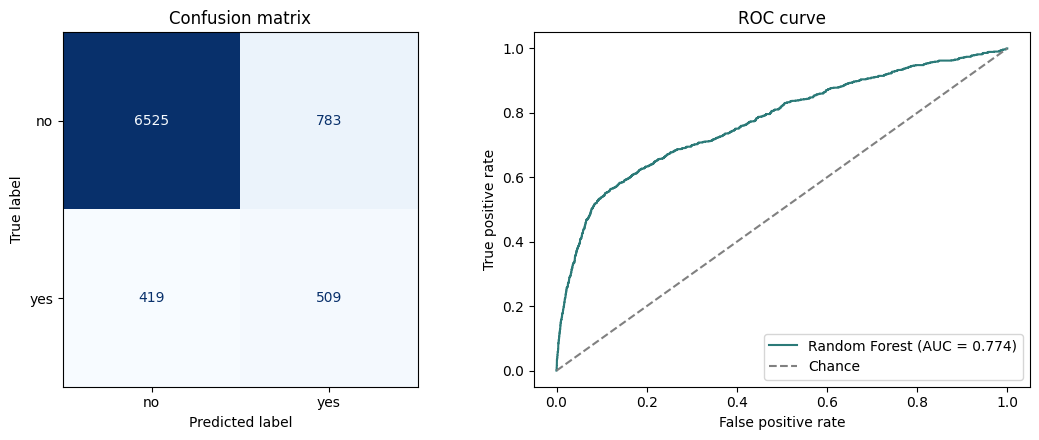

In [10]:
print(classification_report(y_test, pred, target_names=["no", "yes"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["no", "yes"]).plot(
    ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title("Confusion matrix")

fpr, tpr, _ = roc_curve(y_test, proba)
axes[1].plot(fpr, tpr, color="#2b7a78", label=f"Random Forest (AUC = {roc_auc_score(y_test, proba):.3f})")
axes[1].plot([0, 1], [0, 1], "--", color="grey", label="Chance")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpretation:** the baseline reaches high accuracy but finds zero subscribers. The forest gives up some accuracy to find more of them (higher recall), which is the useful trade-off for a marketing campaign. Precision is modest because subscribers are rare.

## 7. Feature importance

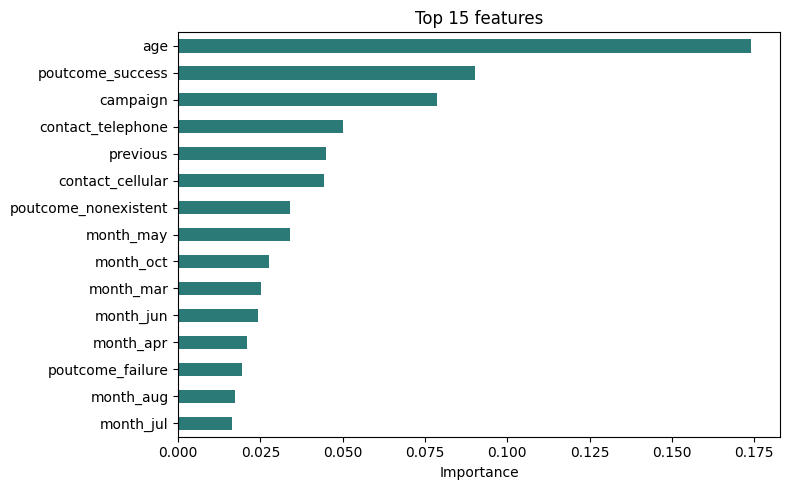

In [11]:
names = pipeline.named_steps["preprocess"].get_feature_names_out()
importances = pipeline.named_steps["model"].feature_importances_
top = pd.Series(importances, index=names).sort_values(ascending=False).head(15)
top.index = [n.split("__", 1)[-1] for n in top.index]

fig, ax = plt.subplots(figsize=(8, 5))
top[::-1].plot(kind="barh", ax=ax, color="#2b7a78")
ax.set_title("Top 15 features")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

## 8. Load the saved model, as the web app does
The app loads `model.joblib` created by `python ml/train_model.py`. This cell loads that file and predicts for one client from the test set.

In [12]:
if not cfg.MODEL_PATH.exists():
    print("model.joblib not found. Run `python ml/train_model.py` from the project root first.")
else:
    saved = joblib.load(cfg.MODEL_PATH)
    client = X_test.iloc[[0]]
    print(client.T)
    p = saved.predict_proba(client)[0, 1]
    print(f"\nPredicted: {'yes' if p >= 0.5 else 'no'} | probability of yes: {p:.3f}")
    print(f"Actual outcome: {'yes' if y_test.iloc[0] == 1 else 'no'}")

                  8489
age                 35
campaign            14
previous             0
job           services
marital        married
education  high.school
housing             no
loan                no
contact      telephone
month              jun
poutcome   nonexistent

Predicted: no | probability of yes: 0.082
Actual outcome: no
